In [1]:
!pip uninstall -y transformers
!pip install transformers==4.52.4


Found existing installation: transformers 4.52.4
Uninstalling transformers-4.52.4:
  Successfully uninstalled transformers-4.52.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.5/10.5 MB 93.5 MB/s eta 0:00:00


In [2]:
!pip install datasets>=2.6.1
!pip install librosa
!pip install evaluate>=0.30
!pip install jiwer
!pip install gradio
!pip install git+https://github.com/openai/whisper.git
!pip install -U gspread
!pip install gspread-dataframe
!pip install sudachipy sudachidict_core

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 38.6 MB/s eta 0:00:00
  Cloning https://github.com/openai/whisper.git to /tmp/pip-req-build-46l4vc7f
  Running command git clone --filter=blob:none --quiet https://github.com/openai/whisper.git /tmp/pip-req-build-46l4vc7f
  Resolved https://github.com/openai/whisper.git to commit c0d2f624c09dc18e709e37c2ad90c039a4eb72a2
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 126.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 97.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 52.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 11.1 MB/s eta 0:00:00
   ━━━━

In [3]:
import pandas as pd
from datasets import Dataset,Audio
from datasets import DatasetDict

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
from google.colab import auth
auth.authenticate_user()
import gspread
from google.auth import default
creds, _ = default()
gc = gspread.authorize(creds)

ws = gc.open_by_url("https://docs.google.com/spreadsheets/d/1WZdCKCovlYurI-DkcAMI23LKQyaiyFTIMiDvICNP_VI/edit?usp=sharing").worksheet("シート1")
records = ws.get_all_records()
df = pd.DataFrame(records)

In [6]:
print(df)

                                                 url  \
0                                         chunk0.wav   
1                                         chunk1.wav   
2                                         chunk2.wav   
3                                         chunk3.wav   
4                                         chunk4.wav   
5  https://drive.google.com/file/d/1x2kC4q7EIqRW-...   
6  https://drive.google.com/file/d/1JGzzF1PiGCxze...   
7  https://drive.google.com/file/d/1S6RkBgDTzePDH...   
8  https://drive.google.com/file/d/16SnyAfNDE5CPY...   
9  https://drive.google.com/file/d/1IjyxXg9zBY8pH...   

                                          colab_path  sampling_rate  \
0  /content/drive/MyDrive/audio_model/output_data...          16000   
1  /content/drive/MyDrive/audio_model/output_data...          16000   
2  /content/drive/MyDrive/audio_model/output_data...          16000   
3  /content/drive/MyDrive/audio_model/output_data...          16000   
4  /content/drive/MyDrive/au

In [7]:
import random

# データフレームの長さに応じて、0.7 の確率で True を返すリストを作る
msk = [random.random() < 0.7 for _ in range(len(df))]
inverse_msk = [not x for x in msk]

# cast_columnは"colab_path"に含まれているデータをAudio形式に変換している（その後処理が後ろ）
train_dataset = Dataset.from_pandas(df[msk]).cast_column("colab_path", Audio(sampling_rate=16000)).rename_column("colab_path", "audio").remove_columns(["sampling_rate"])
validate_dataset = Dataset.from_pandas(df[inverse_msk]).cast_column("colab_path", Audio(sampling_rate=16000)).rename_column("colab_path", "audio").remove_columns(["sampling_rate"])

In [8]:
print(train_dataset[0])

{'url': 'chunk0.wav', 'audio': {'path': '/content/drive/MyDrive/audio_model/output_data/chunk0.wav', 'array': array([0.        , 0.        , 0.        , ..., 0.00916471, 0.01024066,
       0.01280076]), 'sampling_rate': 16000}, 'correct': 'はいじゃあ知能情報システム第7回機会学習の授業を始めたいと思います第7回目の今日の講義は教師なし学習のその2ということでやっていきたいと思います本日の講義内容に関してはクラスタリングについて引き続き学んでいきます目次としましては前回の問題の解説その後にK-means法によるクラスタリングそして密度法によるクラスタリングを扱います', 'whisper': 'はいじゃあ知能情報システム第7回機会学習の授業を始めたいと思います第7回目の今日の講義は教師なし学習のその2ということでやっていきたいと思います本日の講義内容に関してはクラスタリングについて引き続き学んでいきます目次としましては前回の問題の解説その後にケース法によるクラスタリング', '__index_level_0__': 0}


In [9]:
print(train_dataset[0]["audio"]["array"]) # Audio型に変換されたもの

[0.         0.         0.         ... 0.00916471 0.01024066 0.01280076]


In [10]:
datasets = DatasetDict({
    "train": train_dataset,
    "validate": validate_dataset
})

In [11]:
# datasetsが辞書形式であることが分かる
print(datasets)
print(datasets["validate"])

DatasetDict({
    train: Dataset({
        features: ['url', 'audio', 'correct', 'whisper', '__index_level_0__'],
        num_rows: 8
    })
    validate: Dataset({
        features: ['url', 'audio', 'correct', 'whisper', '__index_level_0__'],
        num_rows: 2
    })
})
Dataset({
    features: ['url', 'audio', 'correct', 'whisper', '__index_level_0__'],
    num_rows: 2
})


In [12]:
import torch
import torchaudio
model_id = "kotoba-tech/kotoba-whisper-v2.0"
device = "cuda" if torch.cuda.is_available() else "cpu"
import whisper
from whisper.audio import N_FRAMES, pad_or_trim, log_mel_spectrogram
from whisper.tokenizer import get_tokenizer
from transformers import WhisperProcessor, WhisperForConditionalGeneration
processor = WhisperProcessor.from_pretrained(model_id)
model = WhisperForConditionalGeneration.from_pretrained(model_id).to(device)
model.config.attn_implementation = "flash_attention_2"
# 下の*.jsonは、モデルに含まれているファイルであり、実際にこれらをダウンロードして音声認識をする

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/340 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

added_tokens.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.51G [00:00<?, ?B/s]

generation_config.json: 0.00B [00:00, ?B/s]

In [13]:
def prepare_dataset(batch):
    audio = batch["audio"]

    # 音響特徴量抽出
    batch["input_features"] = processor.feature_extractor(audio["array"], sampling_rate=audio["sampling_rate"]).input_features[0]

    # 正解のテキストをlabel idにエンコード
    batch["labels"] = processor.tokenizer(batch["correct"]).input_ids
    return batch

In [14]:
batch = datasets['train'][0]
audio = batch["audio"]

batch["input_features"] = processor.feature_extractor(audio["array"], sampling_rate=audio["sampling_rate"]).input_features[0]
#print("processor.feature_extractorの出力")
#print(processor.feature_extractor(audio["array"], sampling_rate=audio["sampling_rate"]))
#print("音声特徴量")
#print(batch['input_features'])
batch["labels"] = processor.tokenizer(batch["correct"]).input_ids
#print("トークン化した結果")
#print(batch['labels'])

In [15]:
prepare_dataset(datasets['train'][0])

{'url': 'chunk0.wav',
 'audio': {'path': '/content/drive/MyDrive/audio_model/output_data/chunk0.wav',
  'array': array([0.        , 0.        , 0.        , ..., 0.00916471, 0.01024066,
         0.01280076]),
  'sampling_rate': 16000},
 'correct': 'はいじゃあ知能情報システム第7回機会学習の授業を始めたいと思います第7回目の今日の講義は教師なし学習のその2ということでやっていきたいと思います本日の講義内容に関してはクラスタリングについて引き続き学んでいきます目次としましては前回の問題の解説その後にK-means法によるクラスタリングそして密度法によるクラスタリングを扱います',
 'whisper': 'はいじゃあ知能情報システム第7回機会学習の授業を始めたいと思います第7回目の今日の講義は教師なし学習のその2ということでやっていきたいと思います本日の講義内容に関してはクラスタリングについて引き続き学んでいきます目次としましては前回の問題の解説その後にケース法によるクラスタリング',
 '__index_level_0__': 0,
 'input_features': array([[-0.6625371 , -0.6625371 , -0.6625371 , ...,  0.33044857,
          0.30225164,  0.40530807],
        [-0.6625371 , -0.6625371 , -0.6625371 , ...,  0.42801303,
          0.3998161 ,  0.5028725 ],
        [-0.6625371 , -0.6625371 , -0.6625371 , ...,  0.42479062,
          0.47381258,  0.5135526 ],
        ...,
        [-0.6625371 , -0.6625371 , -0.6625371 , ...,  0.01880676,


In [16]:
prepared_datasets = datasets.map(prepare_dataset, remove_columns=datasets.column_names["train"], num_proc=1)
# datasetsをmapに対して使用するためにdatasets.mapとしている
# map()はHugging FaceのDataset型にのみ利用可能で、DatasetDictの中の各キーの中のDatasetに対して一行ずつ順に関数を割り当てていってる
# num_procは並列処理の数（増やすとうまくいかないらしいから1のまま)

# これをふまえたうえで、関数prepare_datasetについてみていく
# まず引数batchは上述より、Dataset内の各行である
# 下の写真が、1行目の内容だが、audioは、パスとAudio型に変換された行列データ、そしてsampling_rateが一緒に辞書形式で保存されていることが分かる
# まずprocessorとは、音声の入力データを特徴量に変換(feature_extractor)そして、テキストとtokenIDとの相互変換(tokenizer)を行うもの
# このprocessorの中のfeature_extractorを用いて（正確には内包されているわけではないが) processor.feature_extractor(Audio_array, sampling_rate)として音声特徴データを作成
# processor.tokenizerは、文字をtokenに変換している。日本語の50音以外にも、単語に一つのトークンが割り与えられたりもしている。（モデルによる）

Map:   0%|          | 0/8 [00:00<?, ? examples/s]

Map:   0%|          | 0/2 [00:00<?, ? examples/s]

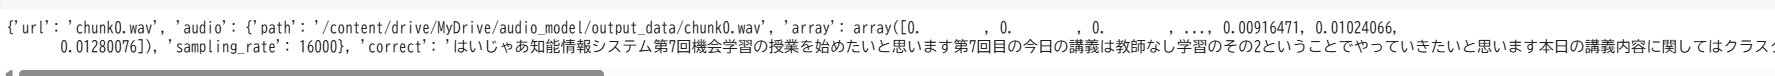

とりあえずここまでで、トレーニングデータと検証データの二つに分割し

音声データは、音声特徴量に変換し、

正解の文章はトークン化させるところまでは終わった


In [17]:
import torch

from dataclasses import dataclass
from typing import Any, Dict, List, Union

@dataclass
class DataCollatorSpeechSeq2SeqWithPadding:
    processor: Any

    def __call__(self, features: List[Dict[str, Union[List[int]
        , torch.Tensor]]]) -> Dict[str, torch.Tensor]:

        #print("padding開始")
        #print('batchごとのfeatures')
        #print(features[0]["labels"])
        # 音響特徴量側をまとめる処理
        # (一応バッチ単位でパディングしているが、すべて30秒分であるはず)
        input_features = [{"input_features": feature["input_features"]} for feature in features]
        batch = self.processor.feature_extractor.pad(input_features, return_tensors="pt")
        # トークン化された正解ラベルをバッチ単位でパディング
        # つまり長さをそろえるために、短いところは0で補うみたいなことをしている
        label_features = [{"input_ids": feature["labels"]} for feature in features]
        labels_batch = self.processor.tokenizer.pad(label_features, return_tensors="pt")
        #print('正解データに関して取り出したやつ')
        #print(label_features)
        #print('それをpaddingしたやつ')
        #print(labels_batch)

        # attention_maskが0の部分は、トークンを-100に置き換えてロス計算時に無視させる
        # attention_maskはpadding下部分を0そうでない部分を1としたもの(tokenizer.padで自動で作成される)
        # -100を無視するのは、PyTorchの仕様
        labels = labels_batch["input_ids"].masked_fill(labels_batch.attention_mask.ne(1), -100)

        #print('0にしたやつを-100に')

        #print(labels[0,:])

        # BOSトークンがある場合は削除
        # labels[:, 0]は、labelsがテンソルなので（2次元ベクトル（行列））、すべての行に対し最初の列の値をとってくるようにという意味
        # labelsには一行あたり1文（元学習用データの一文が保存されてる）
        # .all() → 全バッチで BOS であることを確認.cpu().item() → Python の bool に変換して if 文で使う
        # 先頭2トークンが BOS と言語トークンなら削除
        # 50258がBOSのIDで、50364が言語のID

        if ((labels[:, 0] == 50258) & (labels[:,1] == 50364)).all():
          labels = labels[:, 2:]

        #print(labels[0,:])

        # 整形したlabelsをバッチにまとめる
        batch["labels"] = labels

        #print('psdding終了')

        return batch

In [18]:
# decoder prompt に使われる forced token ID を直接取得
prompt_ids = processor.get_decoder_prompt_ids(language="ja", task="transcribe")
print(prompt_ids)


[(1, 50266), (2, 50360), (3, 50364)]


In [19]:
data_collator = DataCollatorSpeechSeq2SeqWithPadding(processor=processor)

In [20]:
for i in range(3):
    print("labels:", prepared_datasets["train"][i]["labels"])

labels: [50258, 50364, 11050, 31284, 6498, 8225, 10570, 17803, 11054, 9550, 22985, 32026, 7536, 22, 8350, 17543, 12949, 29618, 34025, 2972, 6900, 230, 27119, 5998, 15476, 11429, 20699, 29707, 7536, 22, 8350, 11386, 2972, 26259, 2972, 11932, 37430, 3065, 21936, 16276, 3203, 2849, 29618, 34025, 2972, 20564, 17, 39341, 31497, 39886, 20699, 29707, 8802, 6890, 2972, 11932, 37430, 34742, 25750, 4108, 5196, 95, 8822, 3065, 10825, 11353, 9550, 12144, 12376, 43017, 4108, 9335, 18549, 41301, 7016, 44985, 7016, 29618, 35356, 47348, 11386, 9487, 3193, 45349, 8822, 3065, 8945, 8350, 2972, 17197, 2972, 17278, 3549, 105, 20564, 5661, 4108, 42, 12, 1398, 599, 11148, 4108, 5591, 4895, 10825, 11353, 9550, 12144, 12376, 43017, 25092, 47838, 13127, 11148, 4108, 5591, 4895, 10825, 11353, 9550, 12144, 12376, 43017, 5998, 3416, 109, 11267, 50257]
labels: [50258, 50364, 13557, 3203, 10825, 11353, 9550, 12144, 12376, 43017, 2972, 6627, 40092, 3193, 45349, 8822, 3065, 10673, 236, 9636, 97, 11389, 28427, 3193, 1

In [ ]:
# 上二つのセルについて
# まずfeaturesが何なのか問題は、featuresはさっき作ったprepared_datasetをバッチごとに自動的にとってきて入力されている
# これは、Seq2SeqTrainerの機能（下のtrainer = のところ)
# 一番下の学習時のログを確認してほしい

In [21]:
import evaluate
from sudachipy import dictionary, tokenizer

# Sudachiのセットアップ
tokenizer_obj = dictionary.Dictionary().create()
mode = tokenizer.Tokenizer.SplitMode.C

def tokenize_japanese(sent_list):
    return [
        " ".join([m.surface() for m in tokenizer_obj.tokenize(sent, mode)])
        for sent in sent_list
    ]

# WERライブラリ
wer_metric = evaluate.load("wer")

# 予測と正解
pred_str = df["whisper"].tolist()  # ← カラム名合わせてね
label_str = df["correct"].tolist()    # ← カラム名合わせてね

# 分かち書き
pred_tok = tokenize_japanese(pred_str)
label_tok = tokenize_japanese(label_str)

# WER計算
wer = 100 * wer_metric.compute(predictions=pred_tok, references=label_tok)
print(f"💡 モデル出力に対する実際の WER: {wer:.2f}%")


💡 モデル出力に対する実際の WER: 38.28%


In [22]:
cer_metric = evaluate.load("cer")
cer = 100 * cer_metric.compute(predictions=pred_str, references=label_str)
print(f"🈂️ CER（文字誤り率）: {cer:.2f}%")

🈂️ CER（文字誤り率）: 36.62%


In [23]:
import evaluate
from sudachipy import tokenizer, dictionary

# Sudachiの準備
tokenizer_obj = dictionary.Dictionary().create()
mode = tokenizer.Tokenizer.SplitMode.C  # 文節レベルの分かち書き

# WER指標の読み込み
metric = evaluate.load("wer")
cer_metric = evaluate.load("cer")

# 分かち書き関数（リストに対応）
def tokenize_japanese(sent_list):
    return [
        " ".join([m.surface() for m in tokenizer_obj.tokenize(sent, mode)])
        for sent in sent_list
    ]

# 評価関数
def compute_metrics(pred):
    pred_ids = pred.predictions # model.generate() の出力
    label_ids = pred.label_ids # 教師データの token ID

    # -100 をパディングIDに変換
    label_ids[label_ids == -100] = processor.tokenizer.pad_token_id

    # トークン列 → 文字列へデコード
    pred_str = processor.tokenizer.batch_decode(pred_ids, skip_special_tokens=True)
    label_str = processor.tokenizer.batch_decode(label_ids, skip_special_tokens=True)

    # 分かち書き
    pred_str_tok = tokenize_japanese(pred_str)
    label_str_tok = tokenize_japanese(label_str)
    #print(pred_str_tok)
    #print(label_str_tok)

    # WER計算（0〜100%）
    cer_score = 100 * cer_metric.compute(predictions=pred_str, references=label_str)
    #wer_score = 100 * metric.compute(predictions=pred_str_tok, references=label_str_tok)

    return {"cer": cer_score}

In [24]:
sentence = "はいじゃあ知能情報システム第7回機会学習の授業を始めたいと思います第7回目の今日の講義は教師なし学習のその2ということでやっていきたいと思います本日の講義内容に関してはクラスタリングについて引き続き学んでいきます目次としましては前回の問題の解説その後にK-means法によるクラスタリングそして密度法によるクラスタリングを扱います"

tokens = tokenize_japanese([sentence])
print(tokens[0])

はい じゃあ 知能 情報 システム 第 7 回 機会 学習 の 授業 を 始め たい と 思い ます 第 7 回 目 の 今日 の 講義 は 教師 なし 学習 の その 2 と いう こと で やっ て いき たい と 思い ます 本日 の 講義 内容 に 関し ては クラスタリング に つい て 引き続き 学ん で いき ます 目次 と し まし て は 前回 の 問題 の 解説 その後 に K - means 法 に よる クラスタリング そして 密度 法 に よる クラスタリング を 扱い ます


In [ ]:
# compute_metricsを作成
# これはGinzaを使うとバージョンの衝突が起きてうまくいかない
# 自分で分かち書きを作り、（これは多分mecab)精度評価をするまでしないといけない
# werで評価する場合は
# import evaluate
# metric = evaluate.load("wer")
# wer = 100 * metric.compute(predictions = pred_str, references=label_str)
# pred_strは予測文章を分かち書きしたもの
# label_strは正解文章を分かち書きしたもの
# write me


In [ ]:
import transformers
print(transformers.__version__)

4.52.4


In [ ]:
import transformers
print(transformers.__file__)

/usr/local/lib/python3.11/dist-packages/transformers/__init__.py


In [ ]:
from transformers import Seq2SeqTrainingArguments
help(Seq2SeqTrainingArguments)

Help on class Seq2SeqTrainingArguments in module transformers.training_args_seq2seq:

class Seq2SeqTrainingArguments(transformers.training_args.TrainingArguments)
 |  Seq2SeqTrainingArguments(output_dir: Optional[str] = None, overwrite_output_dir: bool = False, do_train: bool = False, do_eval: bool = False, do_predict: bool = False, eval_strategy: Union[transformers.trainer_utils.IntervalStrategy, str] = 'no', prediction_loss_only: bool = False, per_device_train_batch_size: int = 8, per_device_eval_batch_size: int = 8, per_gpu_train_batch_size: Optional[int] = None, per_gpu_eval_batch_size: Optional[int] = None, gradient_accumulation_steps: int = 1, eval_accumulation_steps: Optional[int] = None, eval_delay: Optional[float] = 0, torch_empty_cache_steps: Optional[int] = None, learning_rate: float = 5e-05, weight_decay: float = 0.0, adam_beta1: float = 0.9, adam_beta2: float = 0.999, adam_epsilon: float = 1e-08, max_grad_norm: float = 1.0, num_train_epochs: float = 3.0, max_steps: int = -

In [27]:
from transformers import Seq2SeqTrainingArguments

training_args = Seq2SeqTrainingArguments(
    output_dir="./test",  # change to a repo name of your choice
    per_device_train_batch_size=16,
    gradient_accumulation_steps=1,   # increase by 2x for every 2x decrease in batch size
    learning_rate=1e-6,
    # warmup_steps=500, # Hugging Faceブログではこちら
    warmup_steps=5,
    # max_steps=4000, # Hugging Faceブログではこちら
    max_steps=2,
    gradient_checkpointing=True,
    fp16=True,
    group_by_length=True,
    eval_strategy="steps",
    per_device_eval_batch_size=8,
    predict_with_generate=True,
    generation_max_length=225,
    # save_steps=1000, # Hugging Faceブログではこちら
    save_steps=1,
    # eval_steps=1000, # Hugging Faceブログではこちら
    eval_steps=1,
    logging_steps=1,
    report_to=["tensorboard"],
    load_best_model_at_end=True,
    metric_for_best_model="cer",
    greater_is_better=False,
    push_to_hub=False)

In [ ]:
import torch
print(torch.cuda.is_available())  # Trueなら使える
print(torch.cuda.get_device_name(0))  # GPUの名前を確認


True
NVIDIA A100-SXM4-40GB


In [28]:
from transformers import Seq2SeqTrainer

trainer = Seq2SeqTrainer(
    args=training_args,
    model=model,
    train_dataset=prepared_datasets["train"],
    eval_dataset=prepared_datasets["validate"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    tokenizer=processor.feature_extractor,
)
trainer.train()

/tmp/ipython-input-28-188242720.py:3: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Seq2SeqTrainer.__init__`. Use `processing_class` instead.
  trainer = Seq2SeqTrainer(


Step,Training Loss,Validation Loss,Cer
1,1.858500,2.276869,48.258706
2,1.858500,2.276869,48.258706


There were missing keys in the checkpoint model loaded: ['proj_out.weight'].


TrainOutput(global_step=2, training_loss=1.8585467338562012, metrics={'train_runtime': 28.7175, 'train_samples_per_second': 1.114, 'train_steps_per_second': 0.07, 'total_flos': 2.534487883776e+16, 'train_loss': 1.8585467338562012, 'epoch': 2.0})

In [ ]:
trainer.save_model("/content/drive/MyDrive/audio_model/unsv_ml_model")
processor.save_pretrained("/content/drive/MyDrive/audio_model/unsv_ml_model")

[]